<>:122: SyntaxWarning: invalid escape sequence '\g'
<>:126: SyntaxWarning: invalid escape sequence '\g'
<>:130: SyntaxWarning: invalid escape sequence '\g'
<>:163: SyntaxWarning: invalid escape sequence '\P'
<>:122: SyntaxWarning: invalid escape sequence '\g'
<>:126: SyntaxWarning: invalid escape sequence '\g'
<>:130: SyntaxWarning: invalid escape sequence '\g'
<>:163: SyntaxWarning: invalid escape sequence '\P'
/tmp/ipykernel_1147/3151938476.py:122: SyntaxWarning: invalid escape sequence '\g'
  ax.errorbar(M_vals, term_cap, yerr=term_cap_err, fmt='--o', color='#789DD1', ecolor='#789DD1', ms = 10 , elinewidth=3, capsize=4, alpha=0.7, label='Cattura Termica (n,$\gamma$)')
/tmp/ipykernel_1147/3151938476.py:126: SyntaxWarning: invalid escape sequence '\g'
  ax.errorbar(M_vals, epi_cap, yerr=epi_cap_err, fmt='--s', color="#F74C08", ecolor='#F74C08', ms = 10 , elinewidth=3, capsize=4, alpha=0.7, label='Cattura Epitermica (n,$\gamma$)')
/tmp/ipykernel_1147/3151938476.py:130: SyntaxWarning: i

Trovati 33 file statepoint. Inizio l'estrazione...


/home/laptop_boz/miniconda3/envs/openmc-env/lib/python3.12/site-packages/openmc/statepoint.py:289: FutureWarning: The 'k_combined' property has been renamed to 'keff' and will be removed in a future version of OpenMC.
  warnings.warn(
/home/laptop_boz/miniconda3/envs/openmc-env/lib/python3.12/site-packages/openmc/statepoint.py:289: FutureWarning: The 'k_combined' property has been renamed to 'keff' and will be removed in a future version of OpenMC.
  warnings.warn(
/home/laptop_boz/miniconda3/envs/openmc-env/lib/python3.12/site-packages/openmc/statepoint.py:289: FutureWarning: The 'k_combined' property has been renamed to 'keff' and will be removed in a future version of OpenMC.
  warnings.warn(
/home/laptop_boz/miniconda3/envs/openmc-env/lib/python3.12/site-packages/openmc/statepoint.py:289: FutureWarning: The 'k_combined' property has been renamed to 'keff' and will be removed in a future version of OpenMC.
  warnings.warn(
/home/laptop_boz/miniconda3/envs/openmc-env/lib/python3.12/s

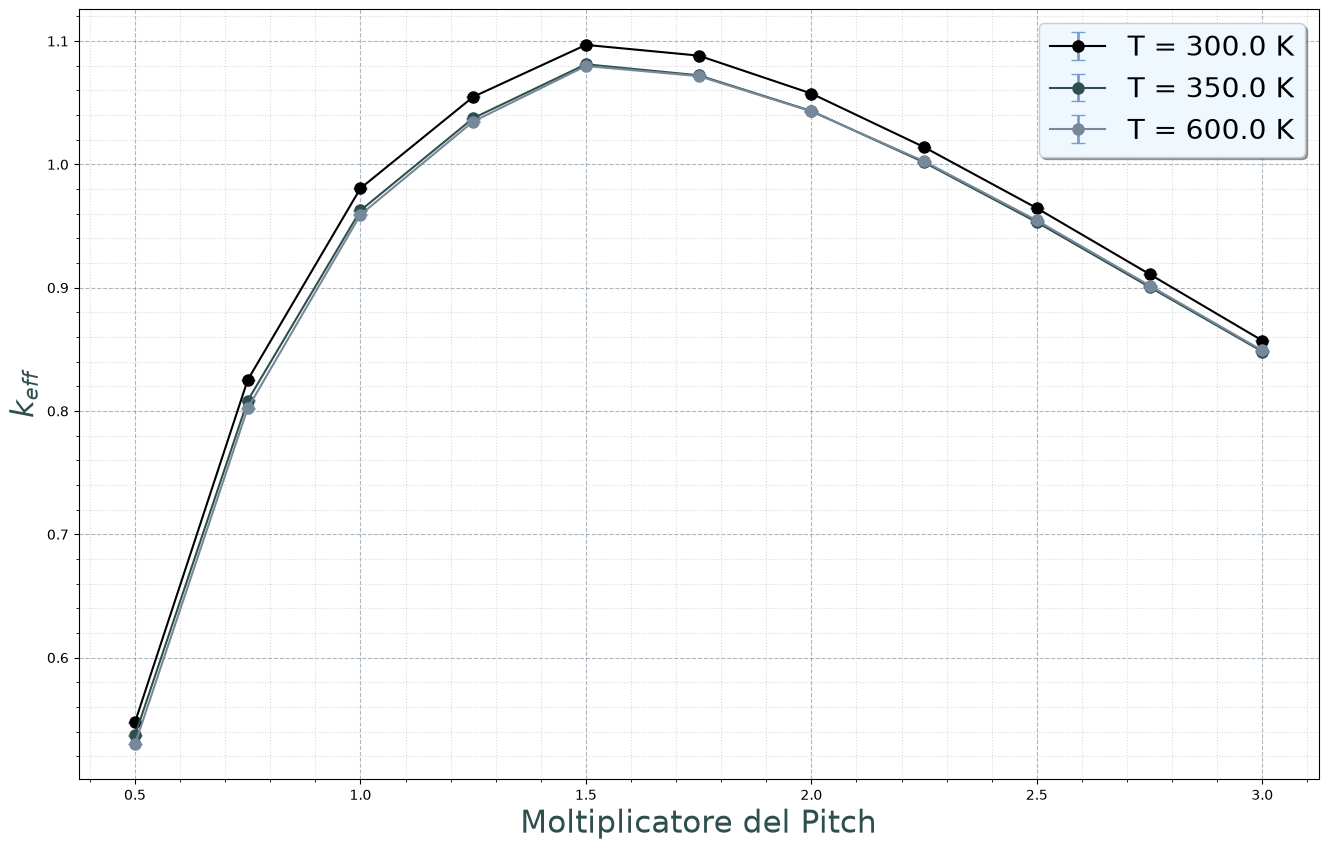

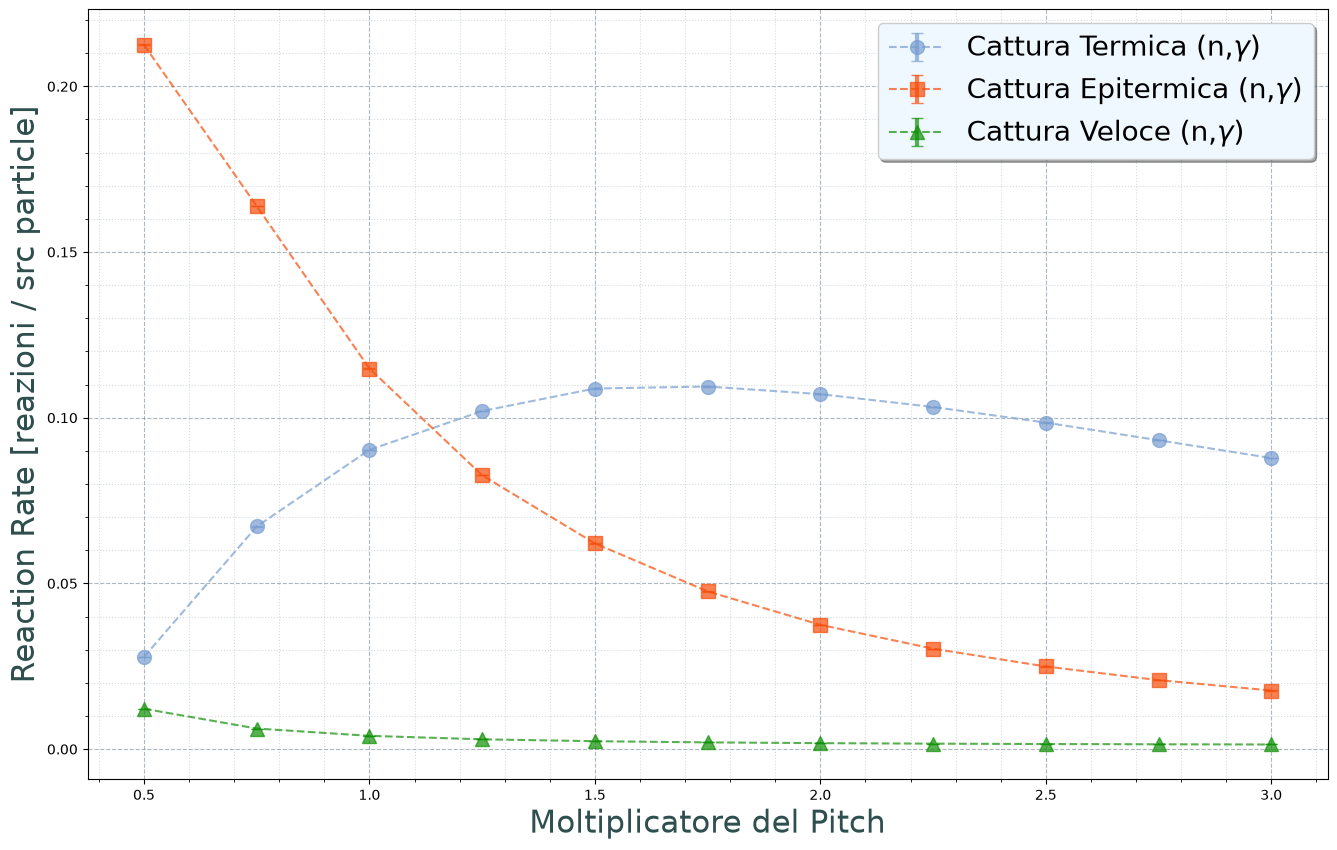

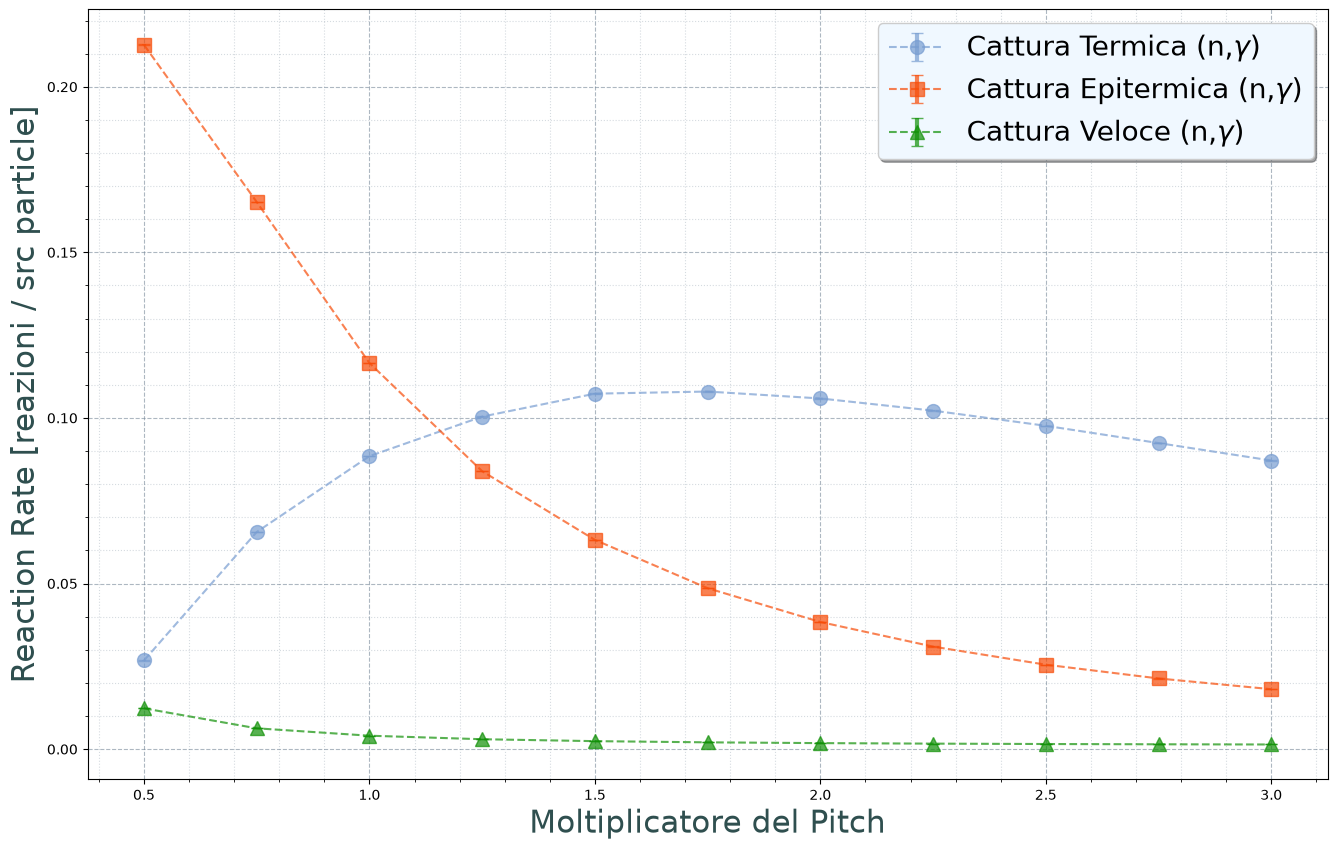

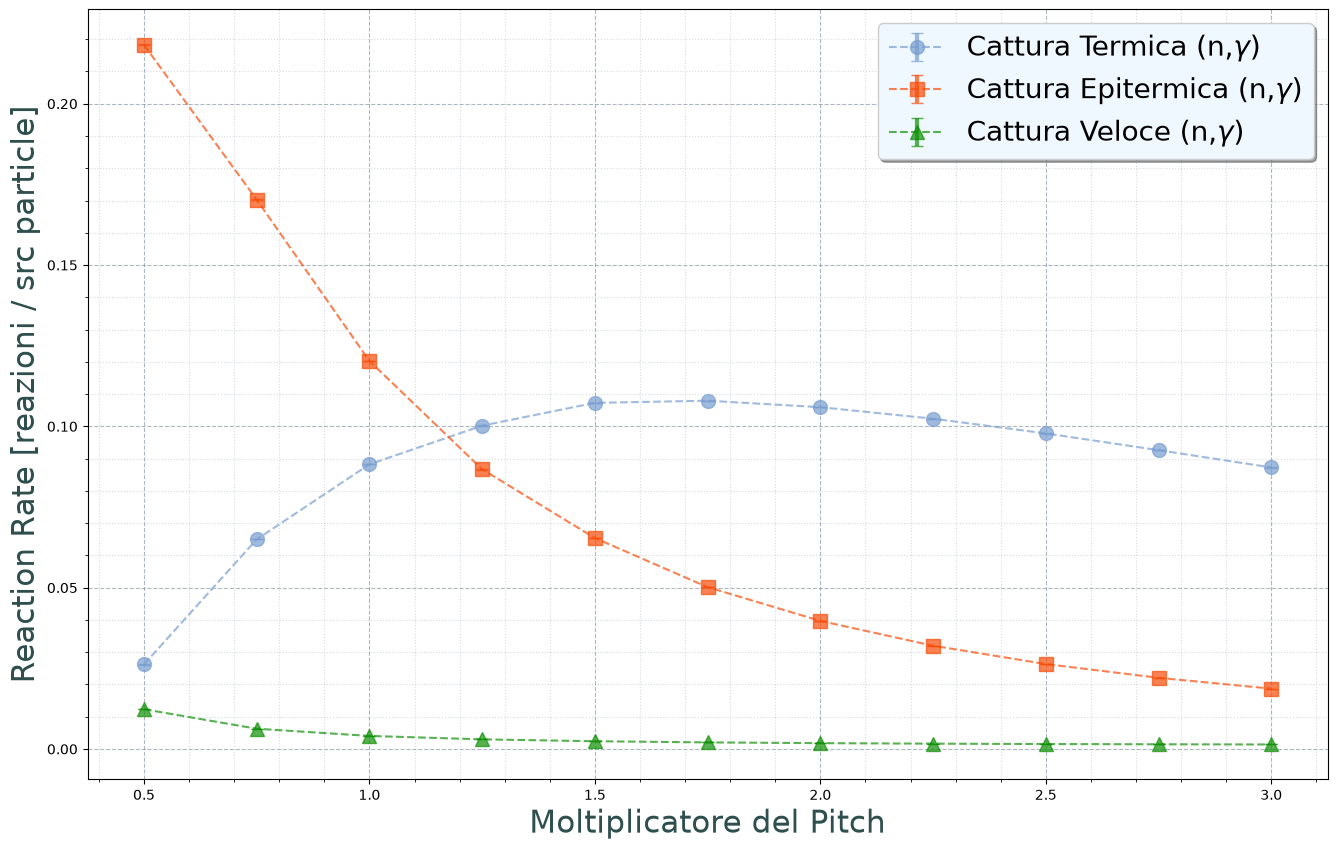

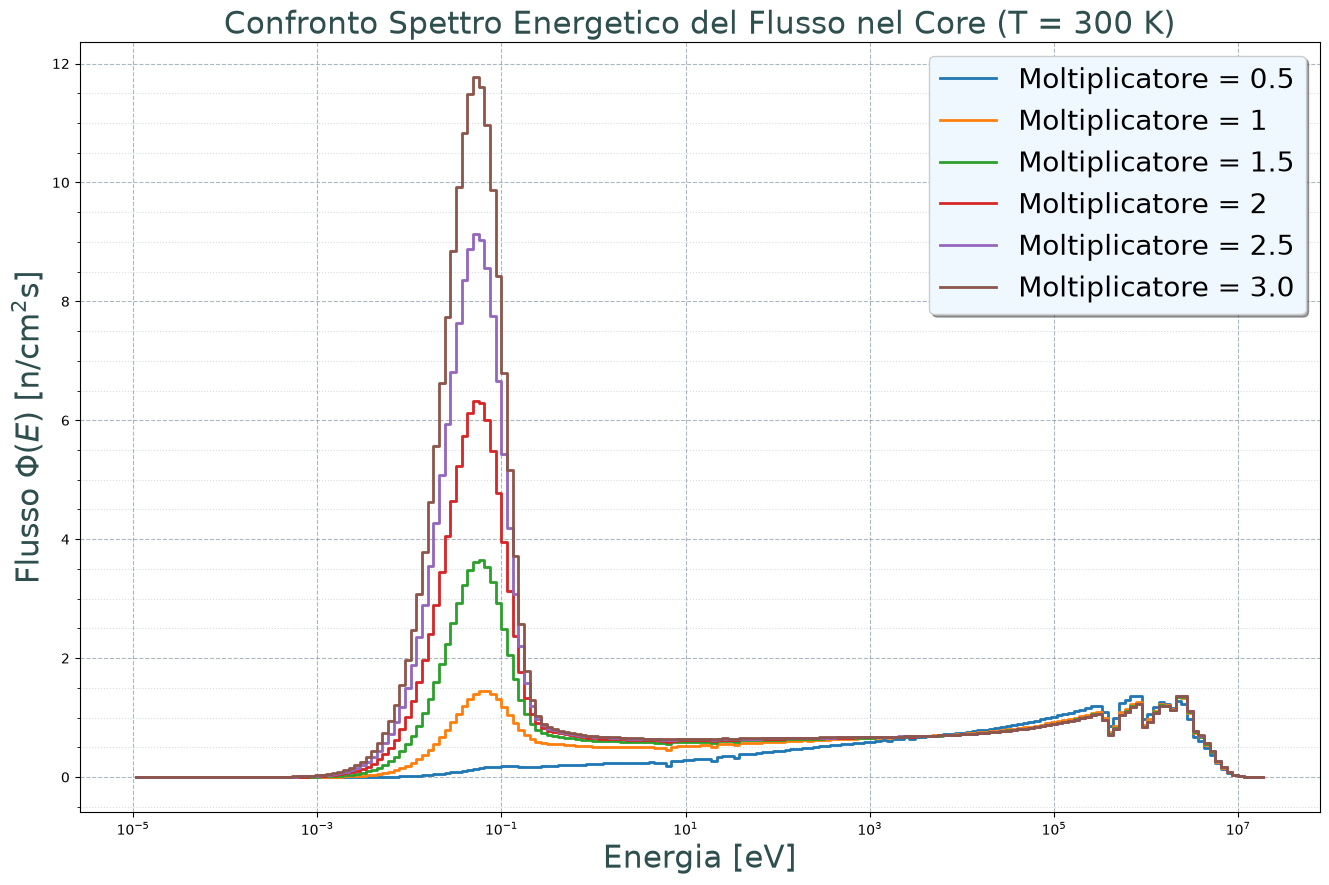

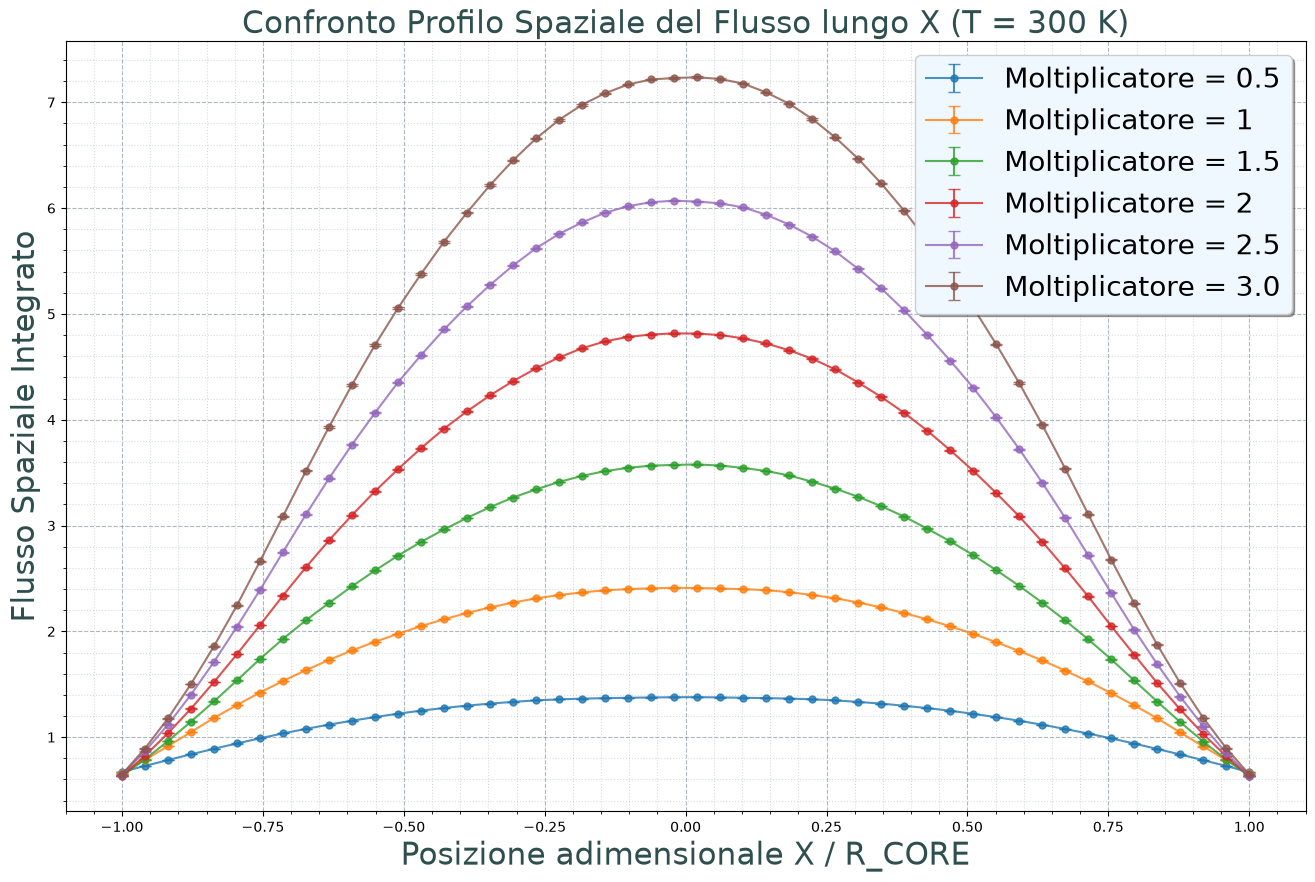

In [9]:
import os
import glob
import re
import openmc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 0. FUNZIONE DI STILE PERSONALIZZATO
# ==========================================
def applica_stile(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel, fontsize=22, color='#2F4F4F')
    ax.set_ylabel(ylabel, fontsize=22, color='#2F4F4F')
    ax.minorticks_on()
    ax.grid(which='major', linestyle='--', alpha=0.6, color='#778899')
    ax.grid(which='minor', linestyle=':', alpha=0.3, color='#778899')
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc='best', frameon=True, shadow=True, fontsize=20, facecolor='#F0F8FF')

# ==========================================
# 1. ESTRAZIONE DATI DAGLI STATEPOINT
# ==========================================
dati_simulazioni = []
file_h5 = glob.glob("statepoint_M*_P*_W*_T*.h5")
pattern = r"statepoint_M([0-9.]+)_P([0-9.]+)_W([0-9.]+)_T([0-9.]+)\.h5"

print(f"Trovati {len(file_h5)} file statepoint. Inizio l'estrazione...")

for file in file_h5:
    match = re.search(pattern, file)
    if match:
        M = float(match.group(1))
        P = float(match.group(2))
        W = float(match.group(3))
        T = float(match.group(4))
        
        with openmc.StatePoint(file) as sp:
            k_val = sp.k_combined.nominal_value
            k_std = sp.k_combined.std_dev
            
            # Flusso continuo
            tally_spectrum = sp.get_tally(name='doppler_flux_spectrum')
            df_spectrum = tally_spectrum.get_pandas_dataframe()
            energies = tally_spectrum.filters[0].bins
            energy_centers = 0.5 * (energies[:, 0] + energies[:, 1])
            
            # Flusso spaziale X
            tally_x = sp.get_tally(name='spatial_flux_x')
            df_x = tally_x.get_pandas_dataframe()
            
            # Assorbimento U-238
            tally_u238 = sp.get_tally(name='u238_absorption_groups')
            df_u238 = tally_u238.get_pandas_dataframe()
            
            dati_simulazioni.append({
                'Moltiplicatore': M, 'Temperatura': T, 'k_eff': k_val, 'k_std': k_std,
                'Energy_Centers': energy_centers,
                'Flux_Spectrum_Mean': df_spectrum['mean'].values,
                'Flux_Spectrum_Std': df_spectrum['std. dev.'].values,  # <--- AGGIUNTO
                'Spatial_Flux_Mean': df_x['mean'].values,
                'Spatial_Flux_Std': df_x['std. dev.'].values,
                'U238_Abs_Data': df_u238
            })

df_results = pd.DataFrame(dati_simulazioni)
df_results = df_results.sort_values(by=['Temperatura', 'Moltiplicatore']).reset_index(drop=True)
temperature_uniche = df_results['Temperatura'].unique()




# ==========================================
# 2. PLOT: K_EFF VS MOLTIPLICATORE PER LE VARIE T
# ==========================================
fig, ax = plt.subplots(figsize=(16, 10))
colori_T = ['#000000', '#2F4F4F', '#778899'] # Colori per distinguere le curve di T

for i, T in enumerate(temperature_uniche):
    df_T = df_results[df_results['Temperatura'] == T]
    ax.errorbar(df_T['Moltiplicatore'], df_T['k_eff'], yerr=df_T['k_std'], 
                fmt='-o', color=colori_T[i % len(colori_T)], ecolor='#789DD1', 
                elinewidth=2, capsize=5, markersize=8, label=f'T = {T} K')

applica_stile(ax, 'Moltiplicatore del Pitch', '$k_{eff}$')
plt.show()

# ==========================================
# 3. I TRE PLOT U-238 (UNO PER OGNI TEMPERATURA)
# ==========================================
for T in temperature_uniche:
    fig, ax = plt.subplots(figsize=(16, 10))
    df_T = df_results[df_results['Temperatura'] == T]
    
    M_vals = df_T['Moltiplicatore'].values
    
    # Inizializziamo le liste per medie ed errori
    term_abs, term_cap, term_abs_err, term_cap_err = [], [], [], []
    epi_abs, epi_cap, epi_abs_err, epi_cap_err = [], [], [], []
    vel_abs, vel_cap, vel_abs_err, vel_cap_err = [], [], [], []
    
    # Estrazione puntuale per ogni moltiplicatore (inclusi gli errori)
    for _, row in df_T.iterrows():
        df_u = row['U238_Abs_Data']
        # 0=Termico, 1=Epitermico, 2=Veloce
        abs_vals = df_u[df_u['score'] == 'absorption']['mean'].values
        cap_vals = df_u[df_u['score'] == '(n,gamma)']['mean'].values
        abs_errs = df_u[df_u['score'] == 'absorption']['std. dev.'].values
        cap_errs = df_u[df_u['score'] == '(n,gamma)']['std. dev.'].values
        
        term_abs.append(abs_vals[0]); term_cap.append(cap_vals[0])
        term_abs_err.append(abs_errs[0]); term_cap_err.append(cap_errs[0])
        
        epi_abs.append(abs_vals[1]);  epi_cap.append(cap_vals[1])
        epi_abs_err.append(abs_errs[1]);  epi_cap_err.append(cap_errs[1])
        
        vel_abs.append(abs_vals[2]);  vel_cap.append(cap_vals[2])
        vel_abs_err.append(abs_errs[2]);  vel_cap_err.append(cap_errs[2])

    # Plot Termico (usando errorbar)
    #ax.errorbar(M_vals, term_abs, yerr=term_abs_err, fmt='-o', color='#2F4F4F', ecolor='#789DD1', capsize=4, linewidth=2, label='Assorbimento Termico')
    ax.errorbar(M_vals, term_cap, yerr=term_cap_err, fmt='--o', color='#789DD1', ecolor='#789DD1', ms = 10 , elinewidth=3, capsize=4, alpha=0.7, label='Cattura Termica (n,$\gamma$)')
    
    # Plot Epitermico (Risonanze)
    #ax.errorbar(M_vals, epi_abs, yerr=epi_abs_err, fmt='-s', color='#789DD1', ecolor='#000000', capsize=4, linewidth=2, label='Assorbimento Epitermico')
    ax.errorbar(M_vals, epi_cap, yerr=epi_cap_err, fmt='--s', color="#F74C08", ecolor='#F74C08', ms = 10 , elinewidth=3, capsize=4, alpha=0.7, label='Cattura Epitermica (n,$\gamma$)')
    
    # Plot Veloce
    #ax.errorbar(M_vals, vel_abs, yerr=vel_abs_err, fmt='-^', color='#000000', ecolor='#789DD1', capsize=4, linewidth=2, label='Assorbimento Veloce')
    ax.errorbar(M_vals, vel_cap, yerr=vel_cap_err, fmt='--^', color="#119107", ecolor='#119107', ms = 10 , elinewidth=3, capsize=4, alpha=0.7, label='Cattura Veloce (n,$\gamma$)')

    #ax.set_yscale('log')
    applica_stile(ax,  
                  'Moltiplicatore del Pitch', 'Reaction Rate [reazioni / src particle]')
    plt.show()

# ==========================================
# 4. CONFRONTO SPETTRO ENERGETICO (A T_BASE = 300K)
# ==========================================
if 300.0 in temperature_uniche:
    fig, ax = plt.subplots(figsize=(16, 10))
    df_300 = df_results[df_results['Temperatura'] == 300.0]
    
    moltiplicatori_da_plottare = [0.5, 1, 1.5, 2, 2.5, 3.0]
    
    for M in moltiplicatori_da_plottare:
        riga = df_300[df_300['Moltiplicatore'] == M]
        if not riga.empty:
            caso = riga.iloc[0]
            energie = caso['Energy_Centers']
            medie = caso['Flux_Spectrum_Mean']
            errori = caso['Flux_Spectrum_Std']
            
            # Tracciamo lo step plot principale
            p = ax.step(energie, medie, where='mid', linewidth=2, label=f'Moltiplicatore = {M}')
            
            # Aggiungiamo una banda d'errore semitrasparente dello stesso colore della linea
            colore_linea = p[0].get_color()
            ax.fill_between(energie, medie - errori, medie + errori, step='mid', color=colore_linea, alpha=0.3)
            
    ax.set_xscale('log')
    applica_stile(ax,
                  'Energia [eV]', 'Flusso $\Phi(E)$ [n/cm$^2$s]')
    plt.title('Confronto Spettro Energetico del Flusso nel Core (T = 300 K)', fontsize=22, color='#2F4F4F')
    plt.show()

# ==========================================
# 5. CONFRONTO PROFILO SPAZIALE LUNGO X (A T_BASE = 300K)
# ==========================================
if 300.0 in temperature_uniche:
    fig, ax = plt.subplots(figsize=(16, 10))
    
    for M in moltiplicatori_da_plottare:
        riga = df_300[df_300['Moltiplicatore'] == M]
        if not riga.empty:
            caso = riga.iloc[0]
            profilo = caso['Spatial_Flux_Mean']
            errore = caso['Spatial_Flux_Std']
            x_bins = np.linspace(-1, 1, len(profilo))
            
            # Lasciando vuoto l'ecolor, Matplotlib assegnerà alle barre d'errore lo stesso colore della linea corrispondente
            ax.errorbar(x_bins, profilo, yerr=errore, fmt='-o', 
                        elinewidth=1.5, capsize=4, markersize=5, alpha=0.8, label=f'Moltiplicatore = {M}')

    applica_stile(ax, 
                  'Posizione adimensionale X / R_CORE', 'Flusso Spaziale Integrato')
    plt.title('Confronto Profilo Spaziale del Flusso lungo X (T = 300 K)', fontsize=22, color='#2F4F4F')
    plt.show()

<>:94: SyntaxWarning: invalid escape sequence '\g'
<>:94: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_1147/579648928.py:94: SyntaxWarning: invalid escape sequence '\g'
  applica_stile(ax, 'Moltiplicatore del Pitch', 'Reaction Rate (n,$\gamma$) [reazioni / src particle]')


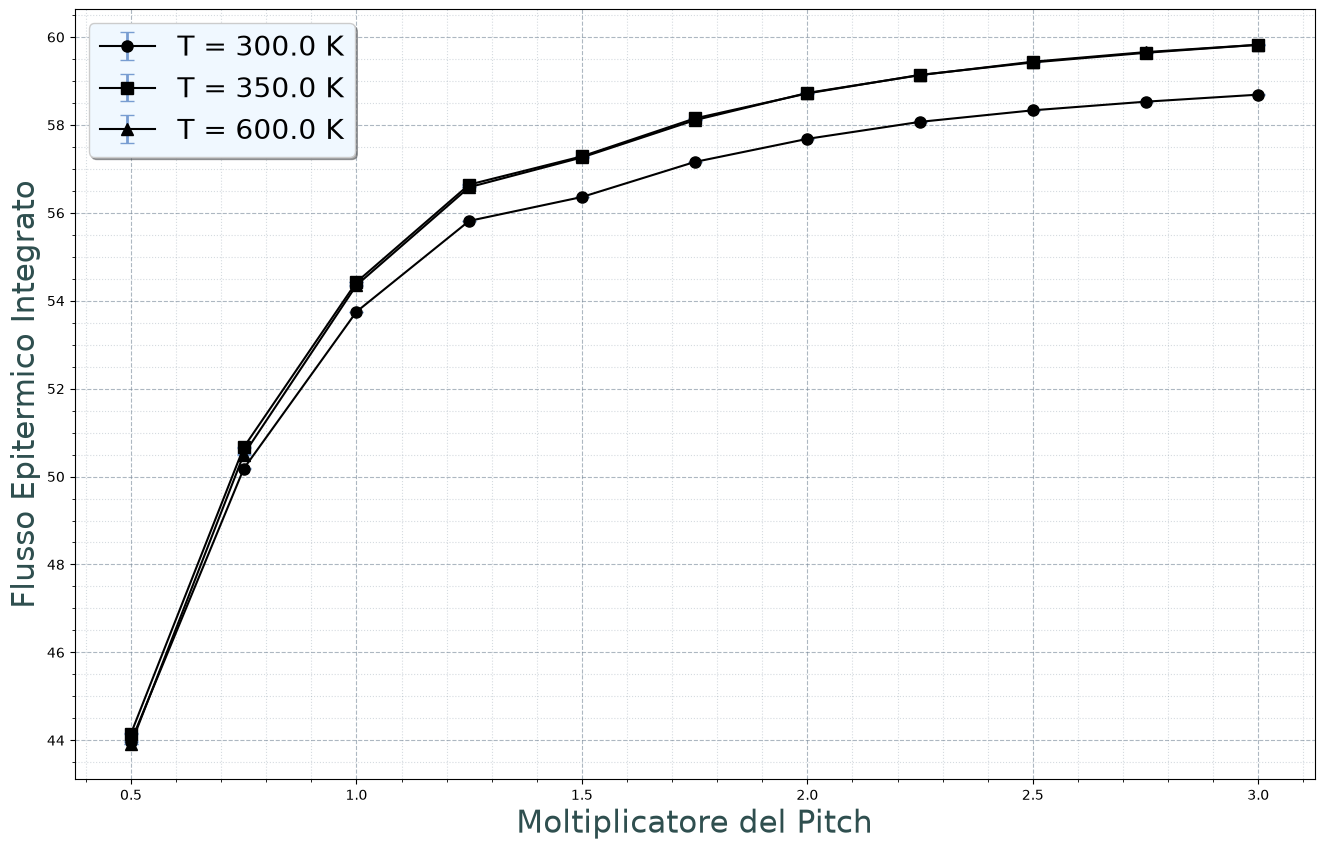

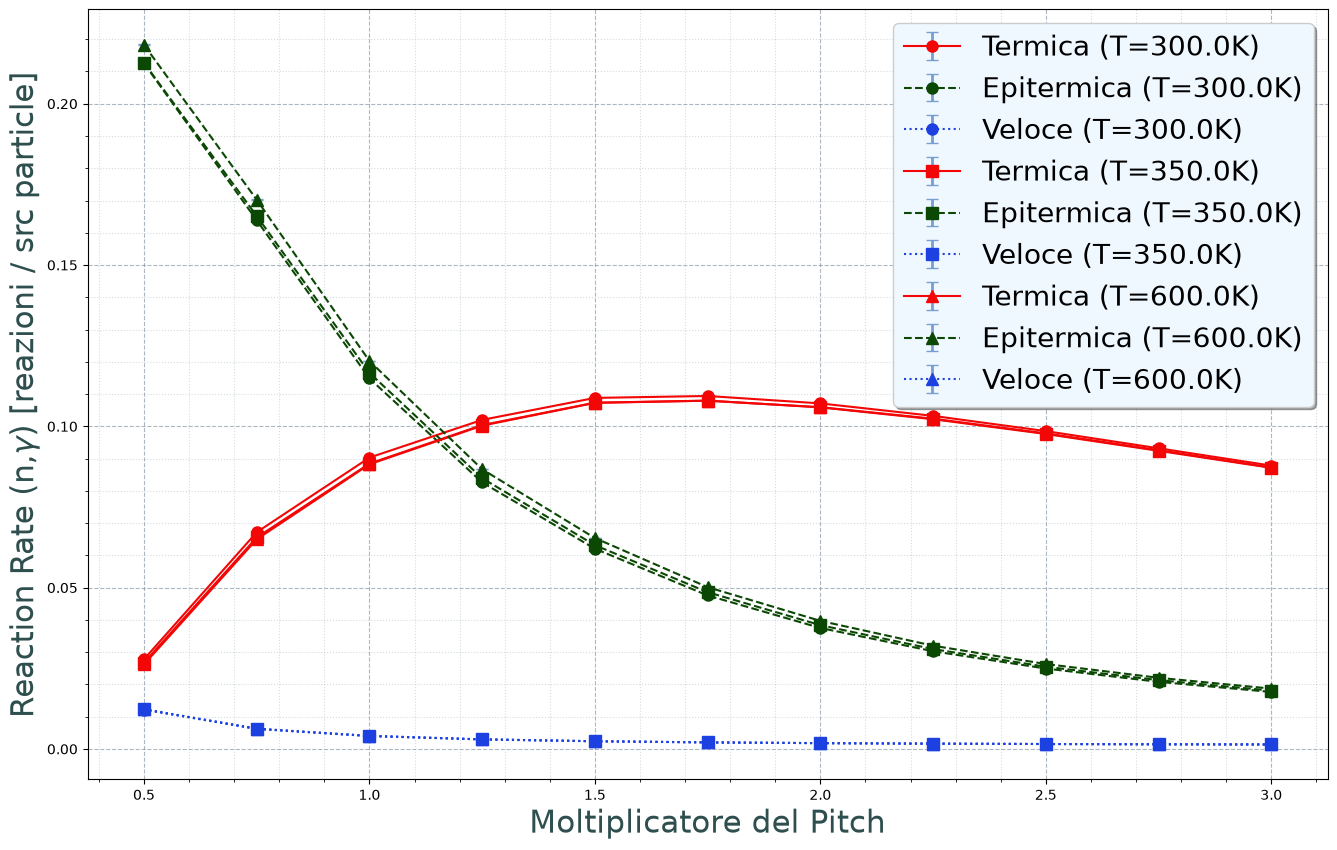

In [10]:
# ==========================================
# 6. INTEGRALE DELLO SPETTRO IN REGIONE EPITERMICA VS PITCH
# ==========================================
fig, ax = plt.subplots(figsize=(16, 10))

# Definizione range epitermico standard (0.625 eV - 100 keV)
E_epi_min = 0.625
E_epi_max = 100.0e3

# Dizionario per assegnare un marker diverso a ogni temperatura
markers = ['o', 's', '^', 'D', 'v']
marker_T = {T: markers[i % len(markers)] for i, T in enumerate(temperature_uniche)}

for T in temperature_uniche:
    df_T = df_results[df_results['Temperatura'] == T]
    M_vals = df_T['Moltiplicatore'].values
    
    flusso_epi_integrato = []
    flusso_epi_err = []
    
    for _, row in df_T.iterrows():
        energie = row['Energy_Centers']
        medie = row['Flux_Spectrum_Mean']
        errori = row['Flux_Spectrum_Std']
        
        # Maschera logica per isolare i bin della regione epitermica
        mask = (energie >= E_epi_min) & (energie <= E_epi_max)
        
        # Integrazione del flusso (somma sui bin della regione)
        flusso_tot = np.sum(medie[mask])
        
        # Propagazione dell'errore (radice della somma dei quadrati)
        err_tot = np.sqrt(np.sum(errori[mask]**2))
        
        flusso_epi_integrato.append(flusso_tot)
        flusso_epi_err.append(err_tot)
        
    ax.errorbar(M_vals, flusso_epi_integrato, yerr=flusso_epi_err,
                fmt=f'-{marker_T[T]}', color='#000000', ecolor='#789DD1',
                elinewidth=2, capsize=5, markersize=8, label=f'T = {T} K')

applica_stile(ax, 'Moltiplicatore del Pitch', 'Flusso Epitermico Integrato')
plt.show()

# ==========================================
# 7. CONFRONTO GLOBALE CATTURE (TERMICA, EPITERMICA, VELOCE)
# ==========================================
fig, ax = plt.subplots(figsize=(16, 10))

# Stili di linea per differenziare la regione energetica (mantenendo il nero)
line_styles = {
    'Termica': '-',
    'Epitermica': '--',
    'Veloce': ':'
}

for T in temperature_uniche:
    df_T = df_results[df_results['Temperatura'] == T]
    M_vals = df_T['Moltiplicatore'].values
    
    term_cap, epi_cap, vel_cap = [], [], []
    term_cap_err, epi_cap_err, vel_cap_err = [], [], []
    
    for _, row in df_T.iterrows():
        df_u = row['U238_Abs_Data']
        # Estraiamo le medie e gli errori per la cattura (n, gamma)
        cap_vals = df_u[df_u['score'] == '(n,gamma)']['mean'].values
        cap_errs = df_u[df_u['score'] == '(n,gamma)']['std. dev.'].values
        
        term_cap.append(cap_vals[0]); term_cap_err.append(cap_errs[0])
        epi_cap.append(cap_vals[1]);  epi_cap_err.append(cap_errs[1])
        vel_cap.append(cap_vals[2]);  vel_cap_err.append(cap_errs[2])
        
    marker = marker_T[T]
    
    # Plot Cattura Termica (Linea continua)
    ax.errorbar(M_vals, term_cap, yerr=term_cap_err, 
                fmt=f'{line_styles["Termica"]}{marker}', 
                color="#F20606", ecolor='#789DD1', ms=8, elinewidth=2, capsize=4, 
                label=f'Termica (T={T}K)')
    
    # Plot Cattura Epitermica (Linea tratteggiata)
    ax.errorbar(M_vals, epi_cap, yerr=epi_cap_err, 
                fmt=f'{line_styles["Epitermica"]}{marker}', 
                color="#0B4804", ecolor='#789DD1', ms=8, elinewidth=2, capsize=4, 
                label=f'Epitermica (T={T}K)')
    
    # Plot Cattura Veloce (Linea punteggiata)
    ax.errorbar(M_vals, vel_cap, yerr=vel_cap_err, 
                fmt=f'{line_styles["Veloce"]}{marker}', 
                color="#1D41E1", ecolor='#789DD1', ms=8, elinewidth=2, capsize=4, 
                label=f'Veloce (T={T}K)')

applica_stile(ax, 'Moltiplicatore del Pitch', 'Reaction Rate (n,$\gamma$) [reazioni / src particle]')
plt.show()

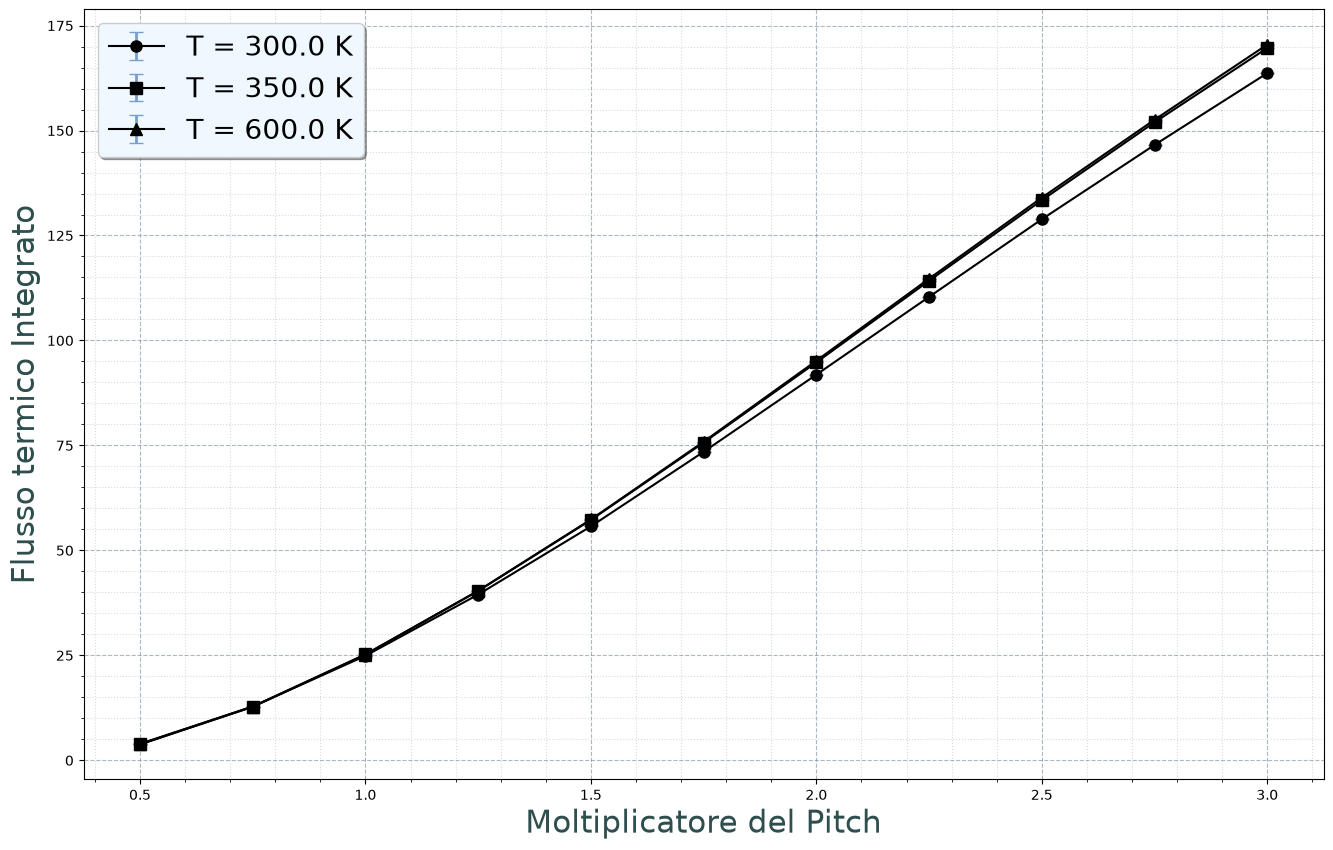

In [11]:
# ==========================================
# 6. INTEGRALE DELLO SPETTRO IN REGIONE TERMICA VS PITCH
# ==========================================
fig, ax = plt.subplots(figsize=(16, 10))

# Definizione range epitermico standard (0.625 eV - 100 keV)
E_epi_min = 0
E_epi_max = 0.625

# Dizionario per assegnare un marker diverso a ogni temperatura
markers = ['o', 's', '^', 'D', 'v']
marker_T = {T: markers[i % len(markers)] for i, T in enumerate(temperature_uniche)}

for T in temperature_uniche:
    df_T = df_results[df_results['Temperatura'] == T]
    M_vals = df_T['Moltiplicatore'].values
    
    flusso_epi_integrato = []
    flusso_epi_err = []
    
    for _, row in df_T.iterrows():
        energie = row['Energy_Centers']
        medie = row['Flux_Spectrum_Mean']
        errori = row['Flux_Spectrum_Std']
        
        # Maschera logica per isolare i bin della regione epitermica
        mask = (energie >= E_epi_min) & (energie <= E_epi_max)
        
        # Integrazione del flusso (somma sui bin della regione)
        flusso_tot = np.sum(medie[mask])
        
        # Propagazione dell'errore (radice della somma dei quadrati)
        err_tot = np.sqrt(np.sum(errori[mask]**2))
        
        flusso_epi_integrato.append(flusso_tot)
        flusso_epi_err.append(err_tot)
        
    ax.errorbar(M_vals, flusso_epi_integrato, yerr=flusso_epi_err,
                fmt=f'-{marker_T[T]}', color='#000000', ecolor='#789DD1',
                elinewidth=2, capsize=5, markersize=8, label=f'T = {T} K')

applica_stile(ax, 'Moltiplicatore del Pitch', 'Flusso termico Integrato')
plt.show()

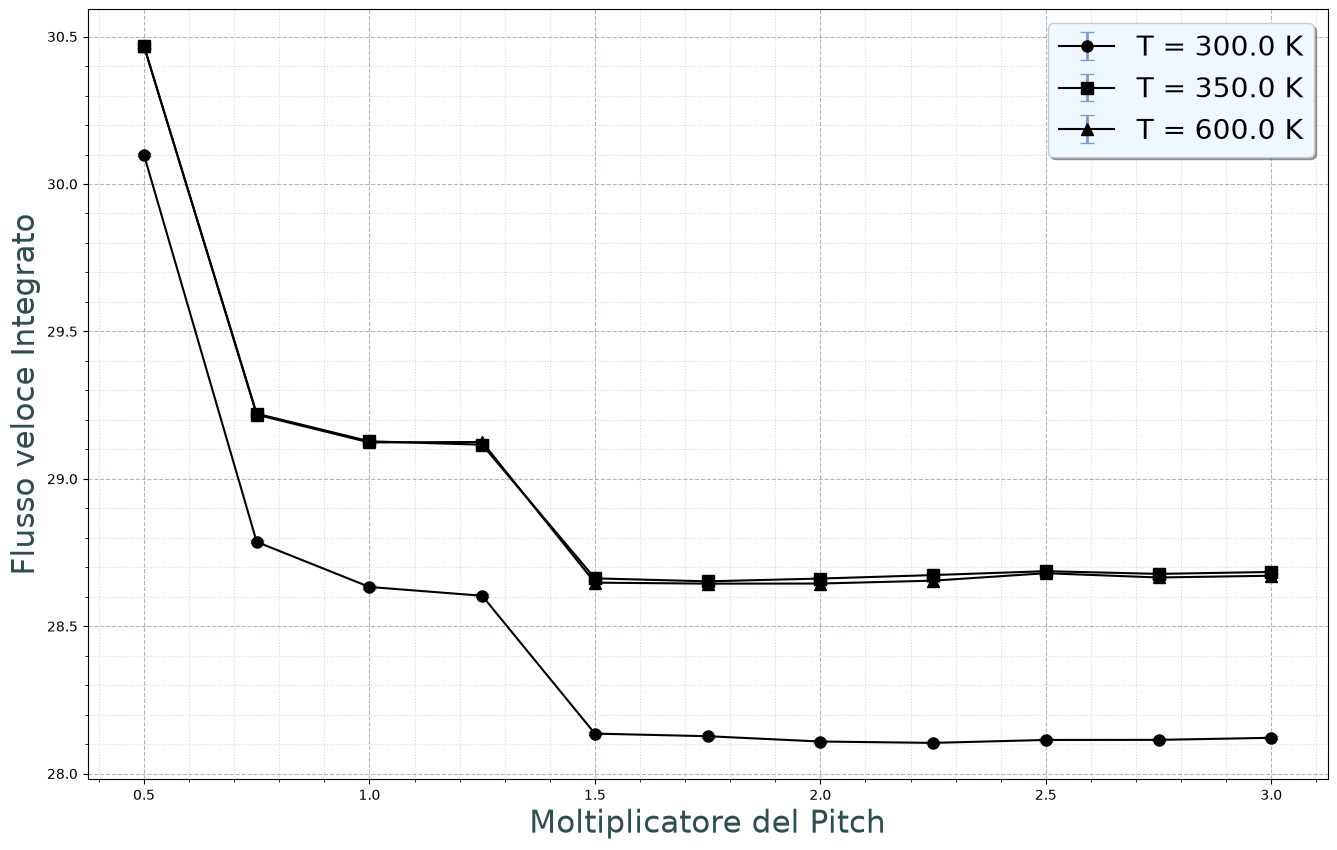

In [12]:
# ==========================================
# 6. INTEGRALE DELLO SPETTRO IN REGIONE EPITERMICA VS PITCH
# ==========================================
fig, ax = plt.subplots(figsize=(16, 10))

# Definizione range epitermico standard (0.625 eV - 100 keV)
E_epi_min = 100.0e3
E_epi_max = 30e6

# Dizionario per assegnare un marker diverso a ogni temperatura
markers = ['o', 's', '^', 'D', 'v']
marker_T = {T: markers[i % len(markers)] for i, T in enumerate(temperature_uniche)}

for T in temperature_uniche:
    df_T = df_results[df_results['Temperatura'] == T]
    M_vals = df_T['Moltiplicatore'].values
    
    flusso_epi_integrato = []
    flusso_epi_err = []
    
    for _, row in df_T.iterrows():
        energie = row['Energy_Centers']
        medie = row['Flux_Spectrum_Mean']
        errori = row['Flux_Spectrum_Std']
        
        # Maschera logica per isolare i bin della regione epitermica
        mask = (energie >= E_epi_min) & (energie <= E_epi_max)
        
        # Integrazione del flusso (somma sui bin della regione)
        flusso_tot = np.sum(medie[mask])
        
        # Propagazione dell'errore (radice della somma dei quadrati)
        err_tot = np.sqrt(np.sum(errori[mask]**2))
        
        flusso_epi_integrato.append(flusso_tot)
        flusso_epi_err.append(err_tot)
        
    ax.errorbar(M_vals, flusso_epi_integrato, yerr=flusso_epi_err,
                fmt=f'-{marker_T[T]}', color='#000000', ecolor='#789DD1',
                elinewidth=2, capsize=5, markersize=8, label=f'T = {T} K')

applica_stile(ax, 'Moltiplicatore del Pitch', 'Flusso veloce Integrato')
plt.show()